# 03 — Two learning systems on the same points

Compare a spiking perceptron with local supervised spike-count updates and a hidden-layer MLP trained by SGD. Both receive the same sampled tasks, but encoding, architecture and learning rule differ together. The accuracy plots compare complete systems; they do not isolate an effect of biological plausibility or update locality.

Section references in the suggested reading refer to the [August background paper](../../paper/background/august-perspective.pdf). For the current talk, use the [slide-to-resource guide](../../talk/resources.md).


In [1]:
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO = os.environ.get("BRAINSMODELS_REPO_URL",
                      "https://github.com/arvidl/brains-to-models-publication.git")
COLAB_ROOT = Path("/content/brains-to-models")

if "google.colab" in sys.modules:
    if not (COLAB_ROOT / "code" / "src" / "brainsmodels").is_dir():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO, str(COLAB_ROOT)])
    root = COLAB_ROOT
else:
    here = Path.cwd().resolve()
    root = here.parents[1] if here.name == "notebooks" else here

src = root / "code" / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.bio_vs_artificial import (
    SmallMLP,
    SpikingPerceptron,
    make_linear,
    make_xor,
    render_paper_figure,
    run_experiment,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

repo root: CHECKOUT
seed: 7


## Two tasks, same plane

Both systems receive a linearly separable dataset and four XOR clusters. These are training-set comparisons. The MLP’s hidden layer changes representational capacity as well as the learning procedure.


In [2]:
x_lin, y_lin = make_linear(n=200, seed=SEED)
x_xor, y_xor = make_xor(n=200, seed=SEED + 1)
print("linear", x_lin.shape, "class balance", y_lin.mean())
print("xor   ", x_xor.shape, "class balance", y_xor.mean())

linear (200, 2) class balance 0.5
xor    (200, 2) class balance 0.5


## A spike train for a point

Each coordinate becomes a Poisson process. Two leaky integrate-and-fire output cells race; the class is who spikes more. The weight $W_{ij}$ sees only the spike count of input $i$ and output $j$ — no error is sent to a hidden layer, because there is none.

point [1.1 0. ]  input spike counts [13.  6.]


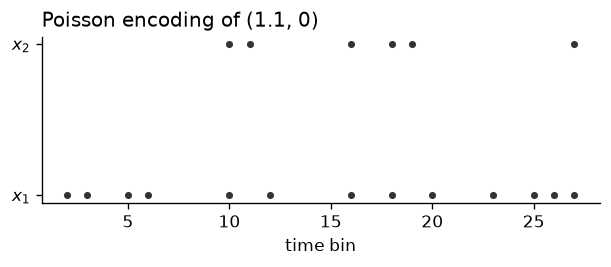

In [3]:
bio = SpikingPerceptron(seed=SEED)
rng = np.random.default_rng(SEED)
pt = np.array([1.1, 0.0])
spikes = bio.encode(pt, rng)
print(f"point {pt}  input spike counts {spikes.sum(axis=0)}")

fig, ax = plt.subplots(figsize=(6.0, 1.8))
for i in range(2):
    times = np.where(spikes[:, i] > 0)[0]
    ax.scatter(times, np.full_like(times, i, dtype=float), s=18, c="0.2", linewidths=0)
ax.set_yticks([0, 1], ["$x_1$", "$x_2$"])
ax.set_xlabel("time bin")
ax.set_title("Poisson encoding of (1.1, 0)", loc="left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## Train both learners

Forty epochs. The LIF net is online (one point, one local update). The MLP uses minibatches and backprop through a 16-unit ReLU layer.

In [4]:
results = run_experiment(seed=SEED, n_epochs=40)
for name, task in results.items():
    print(f"{name:7s}  LIF {task.acc_bio[-1]:.2f}   MLP {task.acc_mlp[-1]:.2f}")

linear   LIF 1.00   MLP 1.00
xor      LIF 0.50   MLP 1.00


## Paper figure

A: linear clouds and both decision regions. B: XOR. C–D: train accuracy. The same call writes the PDF the paper includes.

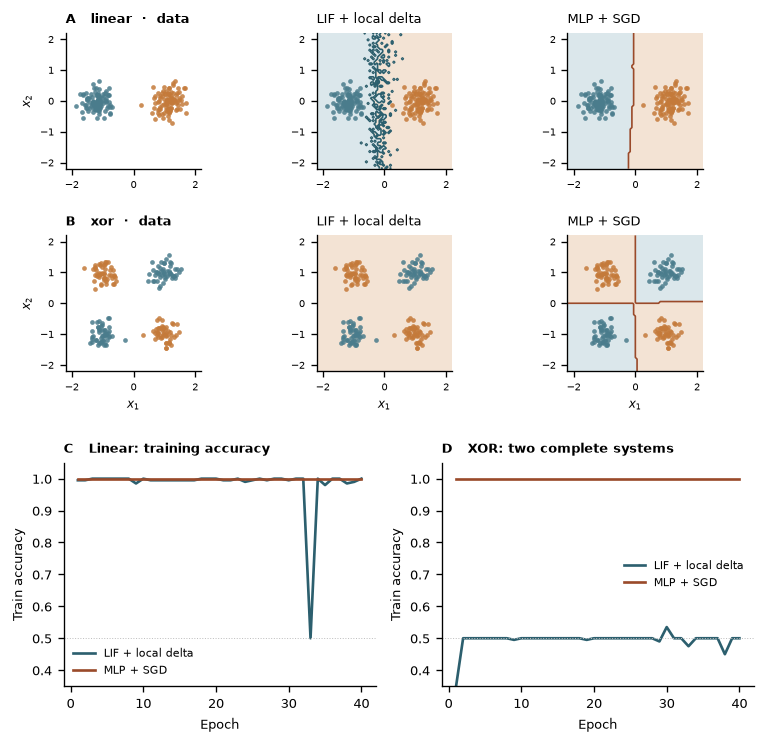

wrote CHECKOUT/paper/figures/bio_vs_artificial.pdf
wrote CHECKOUT/paper/figures/bio_vs_artificial.png


PosixPath('CHECKOUT/paper/figures/bio_vs_artificial.pdf')

In [5]:
fig = render_paper_figure(results)
plt.show()
write_figure(results, root / "paper" / "figures")

## What to notice

Report the observed training accuracies without attributing their difference to a single cause. SGD can be used online, and a spiking model can be frozen. Neither continual learning nor an energy advantage is measured here.


### Exercises

1. **Architecture and update-rule confounds.** Report XOR training accuracy for the spiking system, the default MLP and an MLP with one hidden unit. Which factors change together, and why does this fail to isolate update locality?

<!-- solution-box: 03_1_xor_needs_a_hidden_layer.py -->
<details>
<summary><strong>Show solution</strong> — Architecture and update-rule confounds</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/03_1_xor_needs_a_hidden_layer.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.bio_vs_artificial import SmallMLP, SpikingPerceptron, make_xor
x, y = make_xor(n=200, seed=SEED)
spk = SpikingPerceptron(seed=SEED)
mlp = SmallMLP(n_hidden=16, seed=SEED)
thin = SmallMLP(n_hidden=1, seed=SEED)
spk.train(x, y, n_epochs=30, seed=SEED)
mlp.train(x, y, n_epochs=30)
thin.train(x, y, n_epochs=30)
print(f"LIF perceptron (2→2, local delta)     acc {np.mean(spk.predict(x, seed=SEED) == y):.2f}")
print(f"MLP 2→16→2, SGD                       acc {np.mean(mlp.predict(x) == y):.2f}")
print(f"MLP 2→1→2, SGD                        acc {np.mean(thin.predict(x) == y):.2f}")
print('The systems differ in encoding, depth and update rule. Report their measured accuracies; this comparison does not isolate the effect of update locality.')
```

</details>
<!-- /solution-box -->


2. **Same points, different update.** On the linearly separable Gaussians both learners succeed. After training, scatter the two weight columns of the LIF net and the first-layer weights of the MLP (plot the 2-D input weights). The decision is similar; the objects that were updated are not. What was incremented in each case?

<!-- solution-box: 03_2_same_points_different_update.py -->
<details>
<summary><strong>Show solution</strong> — Same points, different update</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/03_2_same_points_different_update.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.bio_vs_artificial import SmallMLP, SpikingPerceptron, make_linear
x, y = make_linear(n=200, seed=SEED)
spk = SpikingPerceptron(seed=SEED)
mlp = SmallMLP(n_hidden=16, seed=SEED)
spk.train(x, y, n_epochs=25, seed=SEED)
mlp.train(x, y, n_epochs=25)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3))
for ax, pts, c, lab in (
    (axes[0], x[y == 0], "#4a7c8c", "class 0"),
    (axes[0], x[y == 1], "#c47a3a", "class 1"),
):
    ax.scatter(pts[:, 0], pts[:, 1], s=12, c=c, label=lab, alpha=0.7)
for k, col in enumerate(("#2c5f6e", "#9a4a2a")):
    w = spk.w[:, k]
    axes[0].arrow(0, 0, w[0], w[1], color=col, width=0.02, head_width=0.12)
    axes[0].set_title("LIF: two columns of W (2×2)", fontsize=9)
axes[0].legend(fontsize=8, frameon=False)
axes[0].set_aspect("equal")

im = axes[1].imshow(mlp.w1.T, cmap="coolwarm", aspect="auto")
axes[1].set_title("MLP: W1 (2 → 16), updated by SGD", fontsize=9)
axes[1].set_xlabel("input dim")
axes[1].set_ylabel("hidden unit")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()
print('The local count-based update and backpropagated gradient update different quantities. Inspect both rules; successful classification alone cannot identify which rule a biological circuit uses.')
```

</details>
<!-- /solution-box -->


3. **Leak is not depth.** Retrain the same spiking architecture on the linear task at leak values 0.05, 0.20 and 0.80 with the same seed. Compare measured training accuracies. Which state dynamics change, and which architectural and learning choices stay fixed?

<!-- solution-box: 03_3_leak_is_not_depth.py -->
<details>
<summary><strong>Show solution</strong> — Leak is not depth</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/03_3_leak_is_not_depth.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.bio_vs_artificial import SpikingPerceptron, make_linear
x, y = make_linear(n=200, seed=SEED)
for leak in (0.05, 0.20, 0.80):
    net = SpikingPerceptron(leak=leak, seed=SEED)
    net.train(x, y, n_epochs=25, seed=SEED)
    acc = float(np.mean(net.predict(x, seed=SEED) == y))
    print(f"leak {leak:.2f}  train acc {acc:.2f}")
print('Leak changes membrane-state decay within a trial. Report its measured effect here; changing leak leaves the architecture and update rule fixed.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. Which factors differ between the two learners?

2. What does the XOR result establish?

3. How does a membrane leak parameter differ from depth?

4. Could either model learn continually?

5. What would a meaningful energy comparison require?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Lillicrap, T. P., Santoro, A., Marris, L., Akerman, C. J., and Hinton, G. (2020).** [*Backpropagation and the brain*](https://www.cs.toronto.edu/~hinton/absps/backpropandbrain.pdf). *Nature Reviews Neuroscience* 21, 335–346. Author PDF.
2. **Yamins, D. L. K., and DiCarlo, J. J. (2016).** [*Using goal-driven deep learning models to understand sensory cortex*](https://doi.org/10.1038/nn.4244). *Nature Neuroscience* 19, 356–365.
3. **Doerig, A., et al. (2023).** [*The neuroconnectionist research programme*](https://konklab.fas.harvard.edu/Papers/Doerig_2023_NRN.pdf). *Nature Reviews Neuroscience* 24, 431–450.
4. **Kriegeskorte, N., Mur, M., and Bandettini, P. (2008).** [*Representational similarity analysis — connecting the branches of systems neuroscience*](https://www.frontiersin.org/articles/10.3389/neuro.06.004.2008/full). *Frontiers in Systems Neuroscience* 2, 4.
5. **Hebb, D. O. (1949).** [*The Organization of Behavior*](https://en.wikipedia.org/wiki/Hebbian_theory). Wiley. Entry via the opened Hebbian-theory page.
6. **Vaswani, A., et al. (2017).** [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762). *NeurIPS* 30. arXiv:1706.03762.
